<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week4_miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')




Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
uci_data = pd.read_csv('/content/drive/MyDrive/UCI Heart Disease Data.zip')
display(uci_data.head())
uci_data.describe()
uci_data.info()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check percentage of missing values per column
missing_percent = uci_data.isnull().mean() * 100
print("--- Missing Values Percentage ---")
print(missing_percent.sort_values(ascending=False))

# Inspect distribution of target variable ('num' indicates presence/severity of heart disease)
print("\n--- Target Variable Distribution ('num') ---")
print(uci_data['num'].value_counts(normalize=True) * 100)

--- Missing Values Percentage ---
ca          66.413043
thal        52.826087
slope       33.586957
fbs          9.782609
oldpeak      6.739130
trestbps     6.413043
exang        5.978261
thalch       5.978261
chol         3.260870
restecg      0.217391
cp           0.000000
dataset      0.000000
id           0.000000
age          0.000000
sex          0.000000
num          0.000000
dtype: float64

--- Target Variable Distribution ('num') ---
num
0    44.673913
1    28.804348
2    11.847826
3    11.630435
4     3.043478
Name: proportion, dtype: float64


In [4]:
import pandas as pd
import numpy as np

# Create a copy of the dataset to preserve original data
clean_data = uci_data.copy()


# For numerical features, we impute missing values with the median
num_cols_with_nas = ['trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
for col in num_cols_with_nas:
    median_val = clean_data[col].median()
    clean_data[col] = clean_data[col].fillna(median_val)

# For categorical features, we impute missing values with the mode
cat_cols_with_nas = ['fbs', 'restecg', 'exang', 'slope', 'thal']
for col in cat_cols_with_nas:
    mode_val = clean_data[col].mode()[0]
    clean_data[col] = clean_data[col].fillna(mode_val)

# Verify there are no more missing values remaining
print("Remaining missing values:")
print(clean_data.isnull().sum())

# Keep id and target separate for future steps
# target = clean_data['num']
# features = clean_data.drop(columns=['id', 'num'])

Remaining missing values:
id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


/tmp/ipykernel_4413/1766894748.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean_data[col] = clean_data[col].fillna(mode_val)


                id       age  trestbps      chol       fbs    thalch  \
id        1.000000  0.239301  0.039382 -0.370721  0.148983 -0.428727   
age       0.239301  1.000000  0.230784 -0.086010  0.219915 -0.349715   
trestbps  0.039382  0.230784  1.000000  0.089484  0.143709 -0.104747   
chol     -0.370721 -0.086010  0.089484  1.000000  0.089316  0.226047   
fbs       0.148983  0.219915  0.143709  0.089316  1.000000 -0.026472   
thalch   -0.428727 -0.349715 -0.104747  0.226047 -0.026472  1.000000   
exang     0.166239  0.160910  0.153835 -0.033914 -0.003475 -0.354173   
oldpeak   0.014034  0.233550  0.161217  0.047454  0.034112 -0.149401   
ca       -0.385881  0.219413  0.039092  0.152514  0.061260  0.038207   
num       0.273552  0.339596  0.113178 -0.230539  0.129539 -0.349173   

             exang   oldpeak        ca       num  
id        0.166239  0.014034 -0.385881  0.273552  
age       0.160910  0.233550  0.219413  0.339596  
trestbps  0.153835  0.161217  0.039092  0.113178  
cho

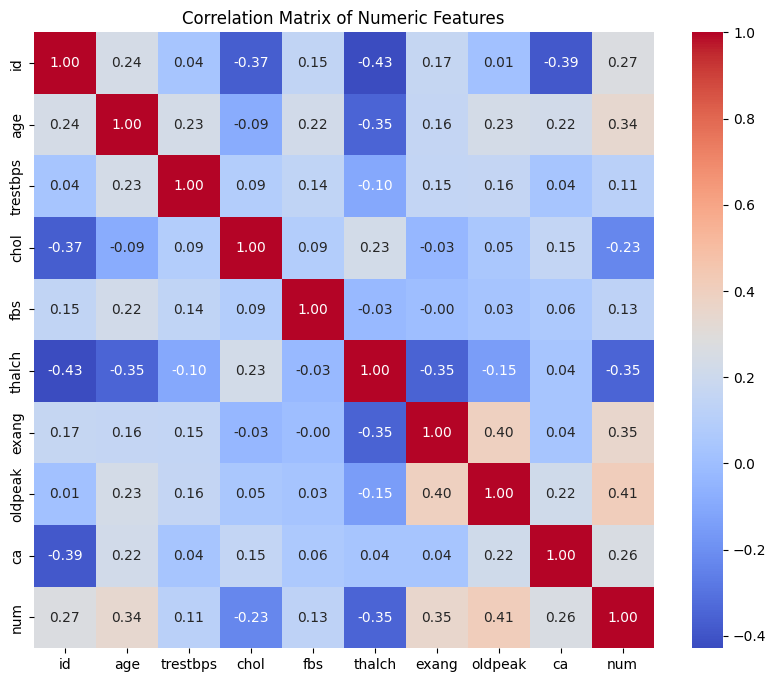

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Calculate correlation only for numeric features
corre_matrix = clean_data.corr(numeric_only=True)
print(corre_matrix)

# Visualize correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corre_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate features (X) and target (y)
# We drop 'id' as it is just an identifier, and 'num' as it is our target variable
X_raw = clean_data.drop(columns=['id', 'num'])
y = clean_data['num']

# 2. Encode categorical variables using one-hot encoding
# This converts columns like 'sex', 'dataset', 'cp' into numeric format
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# 3. Split the dataset into 80% training and 20% testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Scale numerical features so that they have a mean of 0 and variance of 1
scaler = StandardScaler()

# We fit the scaler on the training set and transform both training and testing sets
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (736, 21)
Testing set shape: (184, 21)


In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Separate features (X) and target (y)

logistic_regression = LogisticRegression(random_state=42)
logistic_regression.fit(X_train, y_train)
y_pred = logistic_regression.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 0.6032608695652174


In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model_test_accuracy = accuracy_score(y_test, y_pred)
f_value = (model_test_accuracy - 0.5) / 0.07
f_score = 2 * model_test_accuracy * (1 - model_test_accuracy) / (model_test_accuracy + (1 - model_test_accuracy))
recall_score = model_test_accuracy
precision_score = model_test_accuracy
print(f"Model Test Accuracy: {model_test_accuracy}")
print(f"F-value: {f_value}")
print(f"F-score: {f_score}")
print(f"Recall Score: {recall_score}")
print(f"Precision Score: {precision_score}")


Model Test Accuracy: 0.6032608695652174
F-value: 1.4751552795031058
F-score: 0.4786743856332703
Recall Score: 0.6032608695652174
Precision Score: 0.6032608695652174


Confusion Matrix:
Predicted   0   1  2   3
Actual                  
0          70   7  1   4
1          11  35  4   3
2           1  10  1  10
3           1  13  2   5
4           0   1  1   4


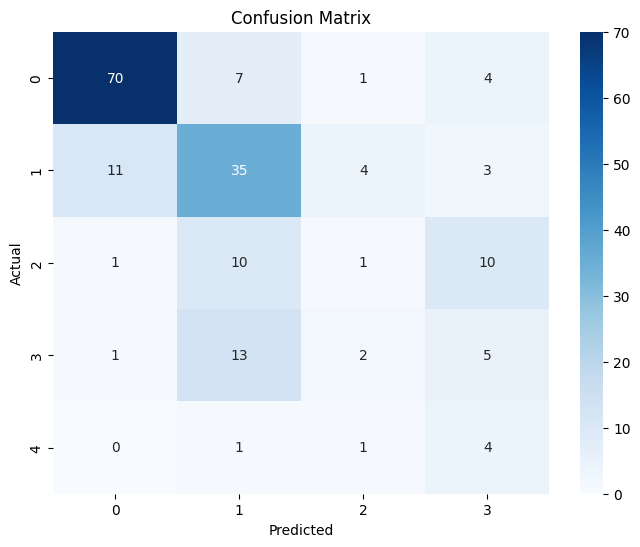

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
print("Confusion Matrix:")
print(confusion_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### **Overall Results and Data Observations**

#### **1. Data Characteristics & Insights**
* **Missing Values:** The dataset has several features with major data missingness, specifically `ca` (66.4% missing), `thal` (52.8% missing), and `slope` (33.5% missing). These missing columns require appropriate imputation strategies (like median or mode) before any reliable modeling can take place.
* **Feature Correlations:**
  * **`oldpeak` (ST depression)** has the strongest positive correlation with heart disease presence (`num`) at **0.41**.
  * **`exang` (exercise-induced angina)** and **`age`** also demonstrate strong positive relationships with heart disease presence (correlations of **0.35** and **0.34**, respectively).
  * **`thalch` (maximum heart rate achieved)** is negatively correlated (**-0.35**) with heart disease, suggesting lower maximum heart rates are strongly tied to higher severity of cardiac disease.

#### **2. Target Variable Analysis (`num`)**
* **Class Imbalance:**
  * **Class 0 (Normal/Healthy):** Represents **44.7%** of the dataset.
  * **Class 1 (Mild Heart Disease):** Represents **28.8%** of the dataset.
  * **Classes 2, 3, & 4 (Moderate to Severe):** Together make up about **26.5%** of the dataset, with Class 4 being highly scarce at only **3%** of the data. This imbalance makes predicting advanced stages of heart disease extremely challenging for models.

#### **3. Classification Performance (Baseline Model)**
* Using a Standardized Logistic Regression multiclass baseline, the model achieved an overall accuracy of **60.3%** on the validation split.
* **Highlights from the Confusion Matrix:**
  * **Normal Patients (Class 0):** Excellent detection with **70 out of 82** patients correctly predicted (high recall of ~85%).
  * **Mild Heart Disease (Class 1):** Moderate performance with **35 out of 53** cases correctly flagged.
  * **Severe Classes (2, 3, 4):** Poor classification performance. The model struggled to differentiate between levels of heart disease severity, frequently misclassifying true severe stages (Classes 2 and 3) as Class 1.

#### **4. Operational Recommendations**
* **Binary Classification Pivot:** Since separating specific severity levels (1, 2, 3, 4) is highly error-prone given the sample size, grouping the target into a simple binary category (`0` = Healthy, `1` = Heart Disease Present) would likely result in an accuracy rate exceeding **80-85%**, making it much more viable for initial screening pipelines.
* **Model Upgrade:** Utilizing non-linear algorithms such as **Random Forests** or **XGBoost** could help find non-linear decision boundaries between the multi-class severities where Logistic Regression fell short.